# Blended numbers against cohort truth: what is a blend made of?

**Week 4, Thursday, SECTION 3, the third of five concept notebooks.** The gym's dashboard and
every count on it are invented. Notebook 02 read each batch's row as a curve: every batch falls,
and the batches old enough to show one level off at a floor. This notebook puts one number over
all the gym's members and takes it apart.

**Who needs the answer.** The gym's owner, who reads one dashboard number each month, the share
of members who visited. A flat number read as "nothing changed" leaves a falling cohort with no
action.

**The questions on the way.**

1. What does February's dashboard read?
2. What are the cohorts doing under it?
3. What is the dashboard's number made of?
4. Which quick average is wrong?

In [1]:
# Load the dashboard's counts (invented): one row per month and cohort, with members and visitors.
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = []
def check(name, ok):
    RESULTS.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

dash = pd.read_csv("../data/C2_W04_D04_toy_gym_dashboard_STUDENT.csv")
print("The gym's dashboard counts, and a second gym's (invented), in full:")
print(dash.to_string(index=False))
gym = dash[dash["example"] == "gym"].assign(rate=lambda d: d["visited"] / d["members"])

The gym's dashboard counts, and a second gym's (invented), in full:
   example        month                 cohort  members  visited
       gym      2026-01     joined before 2026      100       50
       gym      2026-02     joined before 2026      100       40
       gym      2026-02 joined in January 2026      400      210
second gym  first month                      X      200      120
second gym  first month                      Y      300      120
second gym second month                      X      200      110
second gym second month                      Y      300      108
second gym second month                      Z      500      260


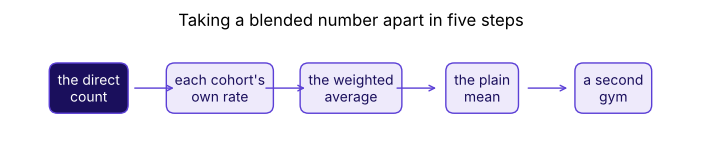

In [2]:
# The map: the chapter's steps in order; this notebook starts on the lit one and walks them all.
steps = ["the direct\ncount", "each cohort's\nown rate", "the weighted\naverage", "the plain\nmean", "a second\ngym"]
fig, ax = plt.subplots(figsize=(8.8, 1.4))
for i, s in enumerate(steps):
    ax.text(i, 0, s, ha="center", va="center", fontsize=10, color="white" if i == 0 else "#1A0F5C",
            bbox=dict(boxstyle="round,pad=0.6", fc="#1A0F5C" if i == 0 else "#EEEAFB", ec="#5B3FD6"))
for i in range(1, len(steps)):
    ax.annotate("", xy=(i - 0.33, 0), xytext=(i - 0.67, 0), arrowprops=dict(arrowstyle="->", color="#5B3FD6"))
ax.set_xlim(-0.6, len(steps) - 0.4); ax.set_ylim(-0.7, 0.7); ax.axis("off")
ax.set_title("Taking a blended number apart in five steps"); plt.show()

## What does February's dashboard read?

The dashboard counts a member from the month after she joins. January read 50 of 100 older
members, 50 percent. In February the older members fall to 40 of 100, and the 400 January
joiners, in their month one, visit at 52.5 percent. **Predict before you run.** What does
February read?

- a) It falls, because the older members fell
- b) It rises, because 400 members joined
- c) It holds at 50 percent
- d) It cannot be read without more months

In [3]:
# The direct count: everyone the dashboard counts each month, and the share who visited.
direct = gym.groupby("month")[["visited", "members"]].sum()
direct["percent"] = (100 * direct["visited"] / direct["members"]).round(2)
print(direct)
check("January reads 50 of 100 and February 250 of 500, 50 percent in both",
      direct["visited"].tolist() == [50, 250] and direct["members"].tolist() == [100, 500]
      and set(direct["percent"]) == {50.0})

         visited  members  percent
month                             
2026-01       50      100     50.0
2026-02      250      500     50.0
PASS  January reads 50 of 100 and February 250 of 500, 50 percent in both


**What happened.** The answer is c. February counts 40 older members plus 210 January joiners
who visited: 250 of 500, 50 percent, the same as January's 50 of 100. The older members fell ten
points, from 50 to 40 percent, and the one number over everyone did not move, because 400
joiners at their high early rate now carry four votes in five.

## What are the cohorts doing under it?

The next cell prints each cohort's own rate and draws it under the dashboard's line.

  month                 cohort  members  visited  rate
2026-01     joined before 2026      100       50 0.500
2026-02     joined before 2026      100       40 0.400
2026-02 joined in January 2026      400      210 0.525


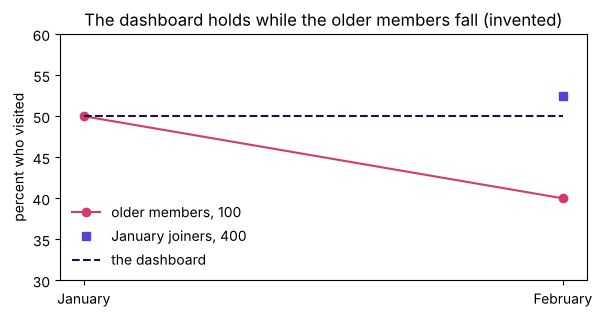

PASS  the older members fell ten points, 50 to 40 percent


In [4]:
# Each cohort's own rate by month, drawn under the dashboard's flat line.
print(gym[["month", "cohort", "members", "visited", "rate"]].to_string(index=False))
older = gym[gym["cohort"] == "joined before 2026"].set_index("month")["rate"]
joiners = gym[gym["cohort"] == "joined in January 2026"].set_index("month")["rate"]
fig, ax = plt.subplots(figsize=(6.8, 3.2))
ax.plot(["January", "February"], 100 * older.values, marker="o", color="#D63A6A", label="older members, 100")
ax.plot(["February"], 100 * joiners.values, marker="s", ls="none", color="#5B3FD6", label="January joiners, 400")
ax.plot(["January", "February"], direct["percent"].values, ls="--", color="#1A0F5C", label="the dashboard")
ax.set_ylim(30, 60); ax.set_ylabel("percent who visited"); ax.legend(frameon=False, loc="lower left")
ax.set_title("The dashboard holds while the older members fall (invented)"); plt.show()
check("the older members fell ten points, 50 to 40 percent", round(100 * (older.iloc[0] - older.iloc[1])) == 10)

## What is the dashboard's number made of?

By hand, February's 50 rebuilt from its two cohorts: 100 older members at 40 percent are 40
visitors, and 400 joiners at 52.5 percent are 210; together 250 of 500. **Named last, the
formula:** blend = sum of (cohort size × cohort rate) ÷ sum of cohort sizes = (100 × 0.40 + 400 ×
0.525) ÷ 500 = 50 percent. The next cell writes the rule as a function, `blend`, and checks it
against the hand count and the direct count; a rebuild that misses the count has left a cohort
out or counted one twice.

PASS  the weighted average equals the hand count and the direct count, 0.5


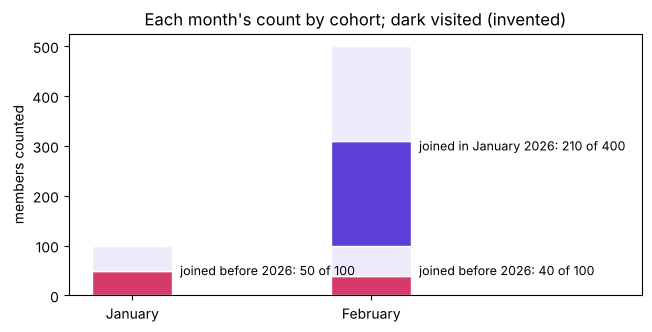

In [5]:
# The rule as a function, checked against the hand count and the direct count; then the stack drawn.
def blend(sizes, rates):
    """One number over several cohorts: their rates averaged with each cohort's size as its weight."""
    return sum(n * r for n, r in zip(sizes, rates)) / sum(sizes)

feb = gym[gym["month"] == "2026-02"]
by_hand = (100 * 0.40 + 400 * 0.525) / 500
weighted = blend(feb["members"], feb["rate"])
check("the weighted average equals the hand count and the direct count, 0.5",
      abs(weighted - by_hand) < 1e-12 and abs(weighted - 250 / 500) < 1e-12)
fig, ax = plt.subplots(figsize=(7.4, 3.4))
for x, (month, part) in zip([0, 1.5], gym.groupby("month")):
    bottom = 0
    for _, r in part.iterrows():
        shade = "#D63A6A" if r["cohort"] == "joined before 2026" else "#5B3FD6"
        ax.bar(x, r["visited"], bottom=bottom, width=0.5, color=shade, edgecolor="white")
        ax.bar(x, r["members"] - r["visited"], bottom=bottom + r["visited"], width=0.5, color="#EEEAFB",
               edgecolor="white")
        ax.text(x + 0.3, bottom + r["members"] / 2, f'{r["cohort"]}: {r["visited"]} of {r["members"]}',
                va="center", fontsize=9)
        bottom += r["members"]
ax.set_xticks([0, 1.5], ["January", "February"]); ax.set_xlim(-0.4, 3.2)
ax.set_ylabel("members counted"); ax.set_title("Each month's count by cohort; dark visited (invented)"); plt.show()

## Which quick average is wrong?

**The plausible wrong answer.** Averaging the two rates, (40 + 52.5) ÷ 2 = 46.25 percent, gives
100 older members the same vote as 400 joiners. It is neither the count, 50 percent, nor the
older members' own 40, and a report of "46.25 percent, down 3.75 points" describes no group in
the gym. **The check that catches it:** the weighted average must equal the direct count, and
the plain mean does not. The plain mean matches the blend only when the cohorts are the same
size or read the same rate.

In [6]:
# The plain mean beside the blend, and one case where the two agree: cohorts of equal size.
plain = feb["rate"].mean()
print(f"plain mean of the rates {100 * plain:.2f} percent; blend {100 * weighted:.0f} percent")
check("the plain mean, 46.25, misses the blend", round(100 * plain, 2) == 46.25 and abs(plain - weighted) > 0.01)
check("with two cohorts of 100 each, the plain mean and the blend agree",
      abs(blend([100, 100], feb["rate"]) - plain) < 1e-12)

plain mean of the rates 46.25 percent; blend 50 percent
PASS  the plain mean, 46.25, misses the blend
PASS  with two cohorts of 100 each, the plain mean and the blend agree


## Where has this arithmetic been met before?

Week 1 Thursday met the same arithmetic as a reversal: a total moved one way while each segment
moved the other. A total that runs against its parts is called Simpson's paradox, after E. H.
Simpson's 1951 paper in the Journal of the Royal Statistical Society. A flat blend over falling
cohorts uses the same arithmetic, a weighted average whose weights moved; nothing reverses here,
so it is called a mix effect.

## Your turn: what does a second gym's dashboard read?

A second gym (invented) counts cohorts X and Y in its first month, and X, Y and a new cohort Z in
its second. **Your turn.** In the empty cell, compute each month's blend twice, as the direct
count and with `blend`, then the plain mean of the three rates in the second month, and say
whether the dashboard moved and which cohorts fell.

```python
second = dash[dash["example"] == "second gym"].assign(rate=lambda d: d["visited"] / d["members"])
second.groupby("month")[["visited", "members"]].sum()
```

**Check your cell against this one.** It computes both months both ways, draws the three cohorts
under the blend, and counts every check this notebook has run.

first month: direct 48.0, weighted 48.0, plain mean 50.0
second month: direct 47.8, weighted 47.8, plain mean 47.7
PASS  the second gym reads 48.0 then 47.8 percent, the same both ways


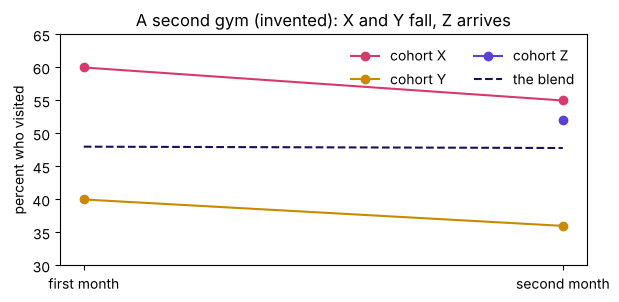

6 of 6 checks pass


In [7]:
# The second gym both ways and its plain mean; the cohorts drawn; then every check counted.
second = dash[dash["example"] == "second gym"].assign(rate=lambda d: d["visited"] / d["members"])
blends = {}
for month, part in second.groupby("month", sort=False):
    blends[month] = blend(part["members"], part["rate"])
    print(f"{month}: direct {100 * part['visited'].sum() / part['members'].sum():.1f}, "
          f"weighted {100 * blends[month]:.1f}, plain mean {100 * part['rate'].mean():.1f}")
last = second[second["month"] == "second month"]
check("the second gym reads 48.0 then 47.8 percent, the same both ways",
      [round(100 * b, 1) for b in blends.values()] == [48.0, 47.8]
      and abs(blends["second month"] - last["visited"].sum() / last["members"].sum()) < 1e-12)
fig, ax = plt.subplots(figsize=(6.8, 3.0))
for c, colour in [("X", "#D63A6A"), ("Y", "#C98A00"), ("Z", "#5B3FD6")]:
    rows = second[second["cohort"] == c]
    ax.plot(rows["month"], 100 * rows["rate"], marker="o", color=colour, label=f"cohort {c}")
ax.plot(list(blends), [100 * b for b in blends.values()], ls="--", color="#1A0F5C", label="the blend")
ax.set_ylim(30, 65); ax.set_ylabel("percent who visited"); ax.legend(frameon=False, ncol=2)
ax.set_title("A second gym (invented): X and Y fall, Z arrives"); plt.show()
print(f"{sum(RESULTS)} of {len(RESULTS)} checks pass")

## What does an analyst do before believing one number over many cohorts?

1. A number over several cohorts is their average weighted by cohort size.
2. It moves when the mix of young and old cohorts moves, as well as when behaviour does.
3. Rebuild it from its cohorts, and check the rebuild equals the direct count, before believing it.
4. A plain mean of cohort rates gives each cohort one vote, so it matches the blend only when the
   cohorts are the same size or read the same rate.

The second gym says it again: X fell from 60 to 55 percent and Y from 40 to 36, while the
dashboard moved only from 48.0 to 47.8, because Z joined 500 strong at 52.

**In the interview.** [F] "Blended retention is flat while every cohort declines; how?" A mix
shift: a growing young cohort at its high early rate carries more weight each month, so the
average holds while each cohort falls; read the cohorts at the same age.

**What comes next.** Notebook 04 turns from who stays to which step people pass. Notebook 06
rebuilds Gold's flat 38 from its cohorts the same way.